# 03explore: candidate findings

**What it does.** Puts five candidate findings side by side, each with its numbers and one draft chart, so the final 3 to 5 can be chosen. Charts are drafts for discussion; the final versions are made for the web page and case study.

1. SRT's arrival (December 2016): did it split the KTX market or grow it?
2. New lines: did the Gangneung line (December 2017) and the Honam high-speed line (April 2015) create riders or move them?
3. COVID: how far below its pre-COVID path is high-speed rail, and has metro rail recovered?
4. Reliability: service disruptions per million train km.
5. The shape of the metro rail day.

**Inputs:** the clean tables in `data/clean` (from `00load`, `01totals`, `02metro`) and `data/names_en.csv` (English names).
**Outputs:** draft charts in `figures/explore/`.

**Data credit:** Korea Railroad Corporation (KORAIL), via data.go.kr, railstat.korail.com and info.korail.com.

## 0. Settings

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from statsmodels.tsa.holtwinters import ExponentialSmoothing

CLEAN = Path("data/clean")  # <- clean tables
NAMES = Path("data/names_en.csv")  # <- English names for stations and lines
FIG = Path("figures/explore")  # <- draft charts

SRT_YEAR_BEFORE = 2016  # <- last year before SRT (SRT ran only from 9 December 2016)
SRT_YEAR_AFTER = 2019  # <- last full year before COVID
TRAIN_START = "2017-01"  # <- forecast trained on KTX plus SRT from here
TRAIN_END = "2019-12"  # <- to here (the last month before COVID)
METRO_BASE = 2019  # <- metro comparison base year
METRO_NOW = 2025  # <- metro comparison latest year

C_BLUE = "#2a78d6"  # <- VISUAL: series 1
C_ORANGE = "#eb6834"  # <- VISUAL: series 2
C_AQUA = "#1baf7a"  # <- VISUAL: series 3
C_GREY = "#a3a29c"  # <- VISUAL: neutral marks
C_TEXT = "#52514e"  # <- VISUAL: text and labels
C_GRID = "#e5e4e0"  # <- VISUAL: grid lines
DPI = 150  # <- VISUAL: resolution of saved charts
FONTS = ["Malgun Gothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]  # <- VISUAL: first font found is used; needs Hangul

FIG.mkdir(parents=True, exist_ok=True)
installed = {f.name for f in font_manager.fontManager.ttflist}
FONTS = [f for f in FONTS if f in installed]
print("chart fonts:", FONTS)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
plt.rcParams.update({"font.size": 9, "text.color": C_TEXT, "axes.labelcolor": C_TEXT, "xtick.color": C_TEXT, "ytick.color": C_TEXT, "axes.edgecolor": C_GRID, "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.family": FONTS})

names = pd.read_csv(NAMES)
EN = dict(zip(names["ko"], names["en"]))
LABEL = {ko: f"{ko} ({en})" for ko, en in EN.items()}  # Hangul first, English in brackets
print("names:", len(LABEL), "| example:", LABEL["부산"], "|", LABEL["경부선"])

chart fonts: ['Malgun Gothic', 'DejaVu Sans']
names: 121 | example: 부산 (Busan) | 경부선 (Gyeongbu Line)


In [2]:
stations = pd.read_csv(CLEAN / "station_year_ktx_srt.csv")
stations["station"] = stations["station"].replace({"여수엑수포": "여수엑스포"})
riders_m = pd.read_csv(CLEAN / "riders_month.csv", parse_dates=["month"], index_col="month")
line_year = pd.read_csv(CLEAN / "line_year.csv")
ktx_month = pd.read_csv(CLEAN / "ktx_station_month.csv", parse_dates=["month"])
runs = pd.read_csv(CLEAN / "runs_year.csv")
events = pd.read_csv(CLEAN / "disruptions_month.csv", parse_dates=["month"])
metro_st = pd.read_csv(CLEAN / "metro_station_month.csv", parse_dates=["month"])
hourly = pd.read_csv(CLEAN / "metro_hourly.csv", parse_dates=["month"])

st = stations.groupby(["operator", "station", "year"])[["board", "alight"]].sum()
st = st.sum(axis=1).unstack("year")
ktx_st = st.loc["KTX"]
srt_st = st.loc["SRT"]
print("KTX stations:", len(ktx_st), "| SRT stations:", len(srt_st))

KTX stations: 81 | SRT stations: 32


## 1. SRT: split the market, or grow it?

Yearly boardings: the line table for 2004 to 2015, the station table from 2016 (it equals the monthly table for KTX).

SRT runs from Suseo in south-east Seoul on the same high-speed line as KTX. At the stations SRT served in 2019, compare KTX in 2016 with KTX and with KTX plus SRT in 2019. Values are boardings plus alightings. Stations that opened after 2016 are left out.

In [3]:
early = line_year[(line_year["line"] == "합계") & (line_year["type"] == "KTX") & (line_year["year"] < 2016)]
early = early.set_index("year")["riders"]
late = stations.groupby(["year", "operator"])["board"].sum().unstack("operator")
hs_year = pd.DataFrame({"KTX": pd.concat([early, late["KTX"]]), "SRT": late["SRT"]}) / 1e6
hs_year = hs_year.fillna(0)
hs_year["both"] = hs_year["KTX"] + hs_year["SRT"]
print("high-speed boardings, millions:")
print(hs_year.round(1).T.to_string())

high-speed boardings, millions:
year  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022   2023   2024
KTX   19.9  32.4  36.5  37.3  38.0  37.5  41.3  50.3  52.4  54.7  56.9  60.5  64.6  59.8  67.0  70.9  43.6  50.5  70.8   84.0   89.9
SRT    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   1.0  19.5  22.0  23.3  17.2  19.6  24.1   26.4   26.7
both  19.9  32.4  36.5  37.3  38.0  37.5  41.3  50.3  52.4  54.7  56.9  60.5  65.6  79.3  89.0  94.2  60.7  70.1  94.9  110.4  116.6


In [4]:
served = srt_st.index[srt_st[SRT_YEAR_AFTER] > 0]
served = [s for s in served if s in ktx_st.index and ktx_st.loc[s, SRT_YEAR_BEFORE] > 0]
srt_eff = pd.DataFrame(index=served)
srt_eff["ktx_before"] = ktx_st.loc[served, SRT_YEAR_BEFORE]
srt_eff["ktx_after"] = ktx_st.loc[served, SRT_YEAR_AFTER]
srt_eff["srt_after"] = srt_st.loc[served, SRT_YEAR_AFTER]
srt_eff["both_after"] = srt_eff["ktx_after"] + srt_eff["srt_after"]
srt_eff["ktx_change_pct"] = (srt_eff["ktx_after"] / srt_eff["ktx_before"] - 1) * 100
srt_eff["both_change_pct"] = (srt_eff["both_after"] / srt_eff["ktx_before"] - 1) * 100
srt_eff["srt_share_pct"] = srt_eff["srt_after"] / srt_eff["both_after"] * 100
srt_eff = srt_eff.sort_values("ktx_before", ascending=False)
srt_eff.index = srt_eff.index.map(LABEL)

tot = srt_eff[["ktx_before", "ktx_after", "both_after"]].sum()
print("stations served by SRT in", SRT_YEAR_AFTER, ":", len(srt_eff))
print("KTX at these stations:", round(tot["ktx_before"] / 1e6, 1), "m ->", round(tot["ktx_after"] / 1e6, 1), "m (", round((tot["ktx_after"] / tot["ktx_before"] - 1) * 100, 1), "% )")
print("KTX plus SRT:", round(tot["both_after"] / 1e6, 1), "m (", round((tot["both_after"] / tot["ktx_before"] - 1) * 100, 1), "% )")
print()
show = srt_eff.copy()
show[["ktx_before", "ktx_after", "srt_after", "both_after"]] = show[["ktx_before", "ktx_after", "srt_after", "both_after"]] / 1e6
print(show.round(1).to_string())

stations served by SRT in 2019 : 14
KTX at these stations: 68.5 m -> 66.3 m ( -3.3 % )
KTX plus SRT: 93.5 m ( 36.4 % )

                          ktx_before  ktx_after  srt_after  both_after  ktx_change_pct  both_change_pct  srt_share_pct
부산 (Busan)                      14.5       12.0        6.1        18.1           -17.6             24.4           33.8
동대구 (Dongdaegu)                 13.4       12.7        5.2        17.9            -5.3             33.6           29.1
대전 (Daejeon)                    10.8       10.3        3.3        13.5            -5.0             25.1           24.1
천안아산 (Cheonan Asan)              6.6        7.1        2.0         9.1             6.6             36.7           22.0
울산 (Ulsan)                       5.6        4.3        0.7         5.0           -22.9             -9.5           14.8
오송 (Osong)                       4.6        6.3        1.8         8.2            36.5             76.1           22.5
광주송정 (Gwangju Songjeong)         4.5        4.5

In [5]:
others = [s for s in ktx_st.index if s not in srt_st.index or srt_st.loc[s, SRT_YEAR_AFTER] == 0]
others = [s for s in others if ktx_st.loc[s, SRT_YEAR_BEFORE] > 0]
o_before = ktx_st.loc[others, SRT_YEAR_BEFORE].sum()
o_after = ktx_st.loc[others, SRT_YEAR_AFTER].sum()
print("comparison: KTX stations not served by SRT, open in both years:", len(others))
print("KTX there:", round(o_before / 1e6, 1), "m ->", round(o_after / 1e6, 1), "m (", round((o_after / o_before - 1) * 100, 1), "% )")

comparison: KTX stations not served by SRT, open in both years: 27
KTX there: 60.7 m -> 68.2 m ( 12.4 % )


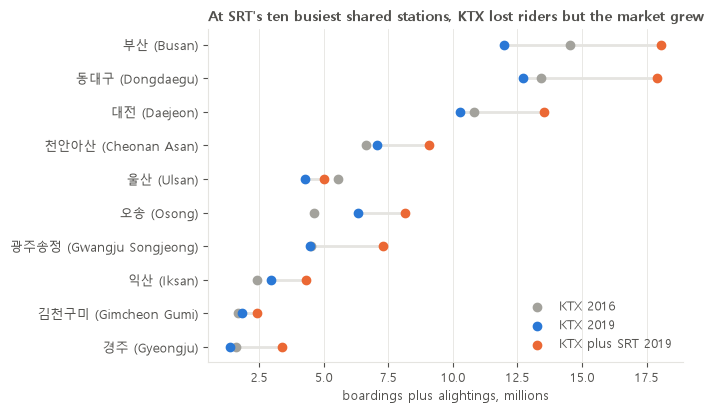

In [6]:
top = srt_eff.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
y = np.arange(len(top))
ax.hlines(y, top["ktx_after"] / 1e6, top["both_after"] / 1e6, color=C_GRID, linewidth=2)
ax.scatter(top["ktx_before"] / 1e6, y, s=36, color=C_GREY, zorder=3, label=f"KTX {SRT_YEAR_BEFORE}")
ax.scatter(top["ktx_after"] / 1e6, y, s=36, color=C_BLUE, zorder=3, label=f"KTX {SRT_YEAR_AFTER}")
ax.scatter(top["both_after"] / 1e6, y, s=36, color=C_ORANGE, zorder=3, label=f"KTX plus SRT {SRT_YEAR_AFTER}")
ax.set_yticks(y, top.index)
ax.set_xlabel("boardings plus alightings, millions")
ax.set_title("At SRT's ten busiest shared stations, KTX lost riders but the market grew")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "f1_srt.png", dpi=DPI)
plt.show()

## 2. New lines: created riders, or moved them?

**Gangneung line (December 2017).** Before it, rail to Gangneung meant slow Mugunghwa and Saemaul trains on the Yeongdong and Taebaek lines. If the KTX only moved existing riders, the old lines should lose about as many as the new line gains.

**Honam high-speed line (April 2015).** KTX to Gwangju moved from Gwangju station to Gwangju Songjeong and got faster. Monthly station data shows the change in the 12 months before and after.

In [7]:
corridor = line_year[line_year["line"].isin(["강릉선", "영동선", "태백선"]) & (line_year["type"] != "total")]
corridor = corridor.groupby(["line", "year"])["riders"].sum().unstack("line").fillna(0) / 1e6
corridor = corridor.rename(columns=EN)
corridor["old lines"] = corridor["Yeongdong Line"] + corridor["Taebaek Line"]
print("riders, millions:")
print(corridor.loc[2013:2024].round(2).to_string())
old_loss = corridor.loc[2016, "old lines"] - corridor.loc[2019, "old lines"]
new_gain = corridor.loc[2019, "Gangneung Line"]
print()
print("2016 to 2019: old lines lost", round(old_loss, 2), "m; Gangneung line carried", round(new_gain, 2), "m")

riders, millions:
line  Gangneung Line  Yeongdong Line  Taebaek Line  old lines
year                                                         
2013            0.00            1.16          0.69       1.85
2014            0.00            1.09          0.64       1.73
2015            0.00            0.84          0.56       1.40
2016            0.00            0.70          0.49       1.19
2017            0.00            0.70          0.45       1.15
2018            2.48            0.56          0.42       0.98
2019            2.57            0.56          0.44       1.01
2020            1.57            0.41          0.24       0.65
2021            1.74            0.47          0.30       0.77
2022            2.32            0.76          0.40       1.16
2023            2.63            0.75          0.46       1.21
2024            2.73            0.88          0.50       1.38

2016 to 2019: old lines lost 0.18 m; Gangneung line carried 2.57 m


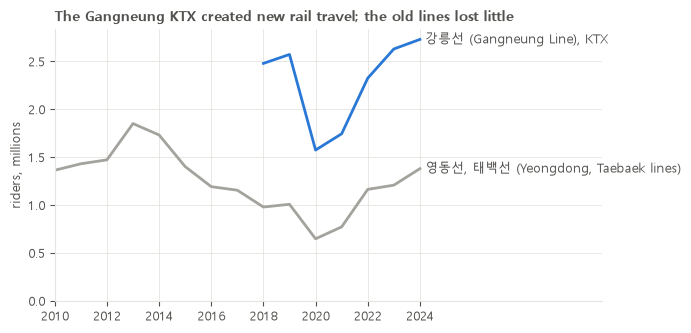

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
c = corridor.loc[2010:2024].copy()
c.loc[c.index < 2018, "Gangneung Line"] = np.nan
ax.plot(c.index, c["Gangneung Line"], color=C_BLUE, linewidth=2)
ax.plot(c.index, c["old lines"], color=C_GREY, linewidth=2)
ax.text(c.index[-1] + 0.2, c["Gangneung Line"].iloc[-1], LABEL["강릉선"] + ", KTX", va="center", color=C_TEXT)
ax.text(c.index[-1] + 0.2, c["old lines"].iloc[-1], "영동선, 태백선 (Yeongdong, Taebaek lines)", va="center", color=C_TEXT)
ax.set_xlim(c.index[0], c.index[-1] + 7)
ax.set_xticks(range(2010, 2025, 2))
ax.set_ylim(0, None)
ax.set_ylabel("riders, millions")
ax.set_title("The Gangneung KTX created new rail travel; the old lines lost little")
fig.tight_layout()
fig.savefig(FIG / "f2_gangneung.png", dpi=DPI)
plt.show()

In [9]:
honam = ["광주", "광주송정", "목포", "나주", "정읍", "익산", "김제", "장성"]
hm = ktx_month[ktx_month["station"].isin(honam)].pivot_table(index="month", columns="station", values="riders_k")
before = hm.loc["2014-04":"2015-03"].sum()
after = hm.loc["2015-04":"2016-03"].sum()
hon = pd.DataFrame({"before_k": before, "after_k": after})
hon["change_pct"] = (hon["after_k"] / hon["before_k"] - 1) * 100
hon.index = hon.index.map(LABEL)
print("KTX boardings plus alightings, thousands, 12 months before and after 2 April 2015:")
print(hon.round(1).to_string())
honam_change = (hon["after_k"].sum() / hon["before_k"].sum() - 1) * 100
print("all eight stations:", round(hon["before_k"].sum()), "->", round(hon["after_k"].sum()), "(", round(honam_change, 1), "% )")

rest = ktx_month[~ktx_month["station"].isin(honam)].pivot_table(index="month", columns="station", values="riders_k")
rest = rest.loc[:, (rest.loc["2014-04":"2016-03"] > 0).all()]
rest_change = (rest.loc["2015-04":"2016-03"].sum().sum() / rest.loc["2014-04":"2015-03"].sum().sum() - 1) * 100
print("comparison: the other", rest.shape[1], "KTX stations open throughout, same windows:", round(rest_change, 1), "%")

KTX boardings plus alightings, thousands, 12 months before and after 2 April 2015:
                          before_k  after_k  change_pct
station                                                
광주 (Gwangju)                1312.0      2.0       -99.8
광주송정 (Gwangju Songjeong)    1243.0   4147.0       233.6
김제 (Gimje)                   109.0      0.0      -100.0
나주 (Naju)                    180.0    479.0       166.1
목포 (Mokpo)                  1058.0   1340.0        26.7
익산 (Iksan)                  1363.0   2115.0        55.2
장성 (Jangseong)               206.0      0.0      -100.0
정읍 (Jeongeup)                407.0    544.0        33.7
all eight stations: 5878 -> 8627 ( 46.8 % )
comparison: the other 32 KTX stations open throughout, same windows: 3.4 %


## 3. COVID: below the old path, and metro rail

A Holt-Winters model (additive trend, multiplicative seasons) is fitted to monthly KTX plus SRT boardings for January 2017 to December 2019, the three full years with both operators and before COVID. Its forecast for 2020 onwards is the path high-speed rail was on. A damped trend gives a more cautious path. 2024 actual comes from the station table (yearly only).

In [10]:
hs_m = (riders_m["KTX"] + riders_m["SRT"]) / 1e6
hs_m = hs_m.asfreq("MS")
train = hs_m[TRAIN_START:TRAIN_END]
fit = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit()
fit_d = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12).fit()
fc = fit.forecast(60)
fc_d = fit_d.forecast(60)

actual_y = hs_m.groupby(hs_m.index.year).sum()
actual_y.loc[2024] = hs_year.loc[2024, "both"]
path = pd.DataFrame({"actual": actual_y, "path": fc.groupby(fc.index.year).sum(), "path_damped": fc_d.groupby(fc_d.index.year).sum()})
path["gap_pct"] = (path["actual"] / path["path"] - 1) * 100
path["gap_damped_pct"] = (path["actual"] / path["path_damped"] - 1) * 100
print("KTX plus SRT boardings, millions:")
print(path.loc[2017:2024].round(1).to_string())
lost = (path["path"] - path["actual"]).loc[2020:2022].sum()
lost_d = (path["path_damped"] - path["actual"]).loc[2020:2022].sum()
print()
print("trips lost against the path, 2020 to 2022:", round(lost), "m (damped:", round(lost_d), "m )")
print("2019 actual:", round(actual_y.loc[2019], 1), "| 2024 actual:", round(actual_y.loc[2024], 1))

KTX plus SRT boardings, millions:
      actual   path  path_damped  gap_pct  gap_damped_pct
2017    79.5    NaN          NaN      NaN             NaN
2018    89.7    NaN          NaN      NaN             NaN
2019    94.9    NaN          NaN      NaN             NaN
2020    60.7  102.5         99.5    -40.8           -39.0
2021    70.1  110.2        102.4    -36.4           -31.6
2022    94.9  117.9        104.4    -19.5            -9.1
2023   110.4  125.6        105.8    -12.1             4.4
2024   116.6  133.2        106.7    -12.5             9.3

trips lost against the path, 2020 to 2022: 105 m (damped: 81 m )
2019 actual: 94.9 | 2024 actual: 116.6


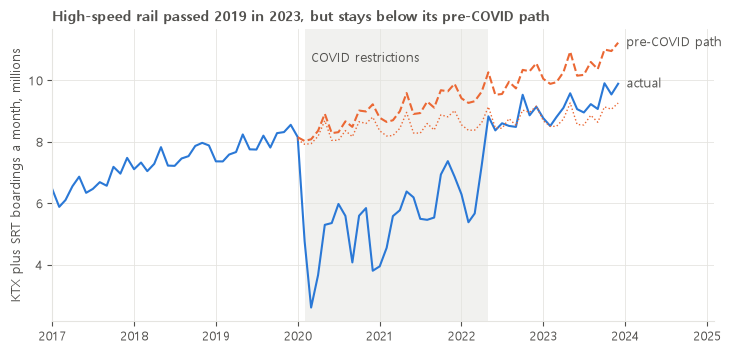

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(hs_m["2017":].index, hs_m["2017":], color=C_BLUE, linewidth=1.5)
ax.plot(fc[:"2023-12"].index, fc[:"2023-12"], color=C_ORANGE, linewidth=1.5, linestyle="--")
ax.plot(fc_d[:"2023-12"].index, fc_d[:"2023-12"], color=C_ORANGE, linewidth=1, linestyle=":")
ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2022-04-30"), color=C_GRID, alpha=0.5, linewidth=0)
ax.text(pd.Timestamp("2023-12-15"), hs_m.iloc[-1], " actual", va="center", color=C_TEXT)
ax.text(pd.Timestamp("2023-12-15"), fc["2023-12"].iloc[0], " pre-COVID path", va="center", color=C_TEXT)
ax.text(pd.Timestamp("2020-03-01"), 10.6, "COVID restrictions", color=C_TEXT)
ax.set_xlim(pd.Timestamp("2017-01-01"), pd.Timestamp("2025-01-31"))
ax.set_ylabel("KTX plus SRT boardings a month, millions")
ax.set_title("High-speed rail passed 2019 in 2023, but stays below its pre-COVID path")
fig.tight_layout()
fig.savefig(FIG / "f3_covid_path.png", dpi=DPI)
plt.show()

In [12]:
ml = metro_st.groupby(["line", "year"])["board"].sum().unstack("year") / 1e6
ml = ml[ml[METRO_BASE].notna()]
ml["change_pct"] = (ml[METRO_NOW] / ml[METRO_BASE] - 1) * 100
ml.index = ml.index.map(LABEL)
ml = ml.sort_values("change_pct")
net_base = metro_st[metro_st["year"] == METRO_BASE]["board"].sum()
net_now = metro_st[metro_st["year"] == METRO_NOW]["board"].sum()
print("metro rail boardings, millions, lines open in both years:")
print(ml.round(1).to_string())
print()
print("network:", round(net_base / 1e6, 1), "->", round(net_now / 1e6, 1), "(", round((net_now / net_base - 1) * 100, 1), "% ), including lines opened since")

metro rail boardings, millions, lines open in both years:
year                      2019   2024   2025  change_pct
line                                                    
경인선 (Gyeongin Line)      116.5   95.2   93.6       -19.7
중앙선 (Jungang Line)        26.0   23.6   22.5       -13.6
ITX-청춘 (ITX-Cheongchun)    6.1    5.4    5.2       -13.4
안산선 (Ansan Line)          47.1   42.6   42.0       -11.0
경원선 (Gyeongwon Line)      99.2   89.4   89.1       -10.1
경부선 (Gyeongbu Line)      193.8  177.9  176.8        -8.7
과천선 (Gwacheon Line)       40.8   37.3   37.6        -7.8
분당선 (Bundang Line)       143.4  138.3  136.9        -4.5
경춘선 (Gyeongchun Line)     14.4   13.8   14.0        -3.4
일산선 (Ilsan Line)          42.0   40.0   41.6        -1.0
경의선 (Gyeongui Line)       41.5   43.7   41.4        -0.2
장항선 (Janghang Line)        5.7    6.6    6.7        18.4
경강선 (Gyeonggang Line)     10.8   12.6   12.8        18.7
수인선 (Suin Line)           16.2   21.7   21.7        34.1
동해선 (Donghae Line)        11.0

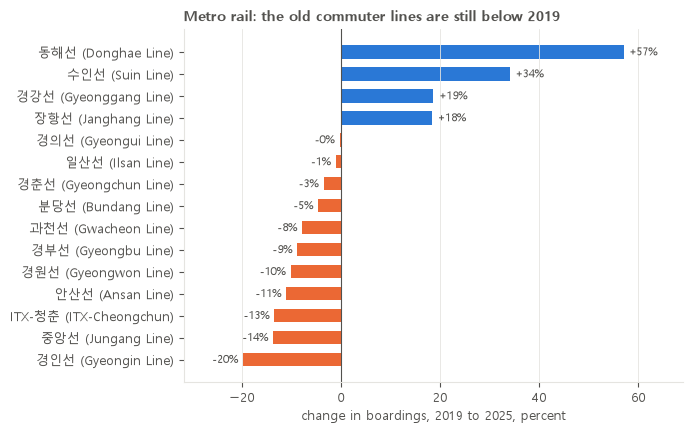

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.4))
colors = [C_ORANGE if v < 0 else C_BLUE for v in ml["change_pct"]]
ax.barh(ml.index, ml["change_pct"], color=colors, height=0.6)
ax.axvline(0, color=C_TEXT, linewidth=0.8)
for i, v in enumerate(ml["change_pct"]):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", color=C_TEXT, fontsize=8)
ax.set_xlabel(f"change in boardings, {METRO_BASE} to {METRO_NOW}, percent")
ax.set_title("Metro rail: the old commuter lines are still below 2019")
ax.grid(axis="y", visible=False)
ax.set_xlim(ml["change_pct"].min() - 12, ml["change_pct"].max() + 12)
fig.tight_layout()
fig.savefig(FIG / "f3b_metro_lines.png", dpi=DPI)
plt.show()

## 4. Reliability: service disruptions per million train km

Train km per year = scheduled train km per day (KORAIL all trains, SR passenger trains) x 365. The unit of the runs table is inferred (see `01totals`), so the rate is an estimate; its trend does not depend on that assumption as long as the unit is the same every year.

In [14]:
ev_y = events.groupby(events["month"].dt.year)[["accidents", "disruptions", "dis_vehicle", "dis_signal", "dis_power"]].sum()
km_day = runs[((runs["operator"] == "KORAIL") & (runs["group"] == "합계")) | ((runs["operator"] == "SR") & (runs["group"] == "여객") & (runs["train_type"] == "소계"))]
km_day = km_day[km_day["train_type"] == "소계"].groupby("year")["train_km_per_day"].sum()
ev_y["train_km_m"] = km_day * 365 / 1e6
ev_y["disruptions_per_m_km"] = ev_y["disruptions"] / ev_y["train_km_m"]
print(ev_y.round(2).to_string())
drop = (ev_y.loc[2022:2024, "disruptions_per_m_km"].mean() / ev_y.loc[2016:2019, "disruptions_per_m_km"].mean() - 1) * 100
print()
print("2022 to 2024 average against 2016 to 2019 average:", round(drop), "%")

       accidents  disruptions  dis_vehicle  dis_signal  dis_power  train_km_m  disruptions_per_m_km
month                                                                                              
2016          16          205          108          11          6      153.40                  1.34
2017          13          179           90          12          7      148.46                  1.21
2018          10          132          103          12          2      160.14                  0.82
2019          20          295          169          25          5      155.65                  1.90
2020           9          146           98          11          6      159.68                  0.91
2021          18           89           56           7          3      153.26                  0.58
2022          28           76           51           4          1      156.56                  0.49
2023          25           75           50           5          1      164.09                  0.46


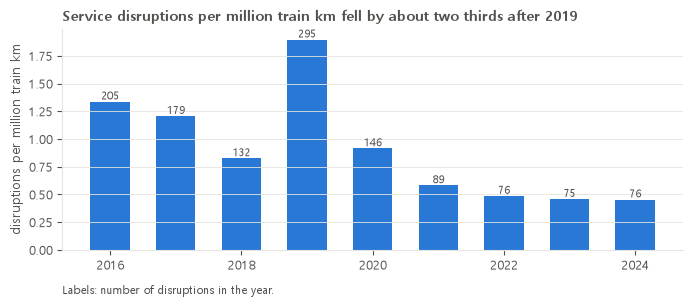

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(ev_y.index, ev_y["disruptions_per_m_km"], color=C_BLUE, width=0.6)
for x, v, n in zip(ev_y.index, ev_y["disruptions_per_m_km"], ev_y["disruptions"]):
    ax.text(x, v + 0.02, f"{n}", ha="center", color=C_TEXT, fontsize=8)
ax.set_ylabel("disruptions per million train km")
ax.set_title("Service disruptions per million train km fell by about two thirds after 2019")
ax.text(0, -0.2, "Labels: number of disruptions in the year.", transform=ax.transAxes, color=C_TEXT, fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "f4_reliability.png", dpi=DPI)
plt.show()

## 5. The shape of the metro rail day

Gate taps by hour, 2025, all months together (weekdays and weekends are not separated in the source). The morning peak share is the share of a line's daily boardings in the 07 and 08 hours.

In [16]:
h25 = hourly[hourly["month"].dt.year == METRO_NOW]
prof = h25.groupby("hour")[["board", "alight"]].sum()
prof = prof / prof.sum() * 100
print("network, percent of the day:")
print(prof.round(1).T.to_string())

by_line = h25.groupby(["line", "hour"])["board"].sum().unstack("hour")
peak = pd.DataFrame({"morning_peak_pct": by_line[[7, 8]].sum(axis=1) / by_line.sum(axis=1) * 100, "evening_peak_pct": by_line[[17, 18]].sum(axis=1) / by_line.sum(axis=1) * 100, "boardings_m": by_line.sum(axis=1) / 1e6})
peak.index = peak.index.map(LABEL)
print()
print(peak.sort_values("morning_peak_pct", ascending=False).round(1).to_string())

network, percent of the day:
hour     6    7    8    9    10   11   12   13   14   15   16   17    18   19   20   21   22   23   24
board   6.6  9.6  9.3  6.1  5.0  4.9  5.2  5.1  5.0  5.7  6.5  7.8   8.2  4.5  3.8  3.2  2.4  1.0  0.1
alight  2.6  4.7  8.7  5.8  4.4  4.3  4.7  4.9  4.9  5.4  6.4  8.1  10.4  8.1  5.2  4.5  3.9  2.5  0.6

                       morning_peak_pct  evening_peak_pct  boardings_m
line                                                                  
중앙선 (Jungang Line)                 24.5              10.8         21.4
경강선 (Gyeonggang Line)              23.7              14.8         12.5
경인선 (Gyeongin Line)                23.0              12.1         94.8
경의선 (Gyeongui Line)                22.7              14.6         40.4
서해선 (Seohae Line)                  22.5              15.2         19.8
경춘선 (Gyeongchun Line)              21.9              12.6         13.9
일산선 (Ilsan Line)                   21.7              13.1         41.1
안산선 (Ansan Line)      

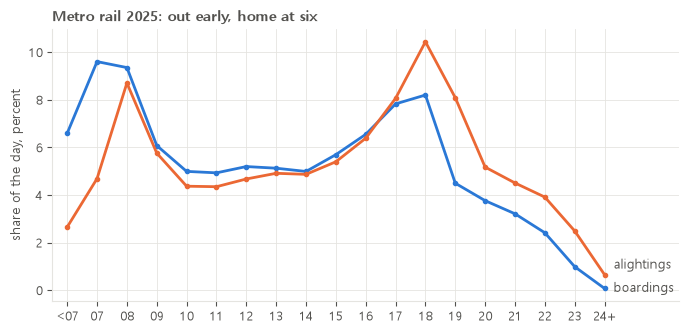

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.4))
hours = prof.index
ax.plot(hours, prof["board"], color=C_BLUE, linewidth=2, marker="o", markersize=3)
ax.plot(hours, prof["alight"], color=C_ORANGE, linewidth=2, marker="o", markersize=3)
ax.text(hours[-1] + 0.3, prof["board"].iloc[-1], "boardings", va="center", color=C_TEXT)
ax.text(hours[-1] + 0.3, prof["alight"].iloc[-1] + 0.4, "alightings", va="center", color=C_TEXT)
ax.set_xticks(hours, ["<07"] + [f"{h:02d}" for h in hours[1:-1]] + ["24+"])
ax.set_xlim(hours[0] - 0.5, hours[-1] + 2.5)
ax.set_ylabel("share of the day, percent")
ax.set_title(f"Metro rail {METRO_NOW}: out early, home at six")
fig.tight_layout()
fig.savefig(FIG / "f5_metro_day.png", dpi=DPI)
plt.show()

## 6. Summary for choosing

In [18]:
print("1. SRT at shared stations: KTX", f"{(tot['ktx_after'] / tot['ktx_before'] - 1) * 100:+.0f}%", "| KTX plus SRT", f"{(tot['both_after'] / tot['ktx_before'] - 1) * 100:+.0f}%", f"({SRT_YEAR_BEFORE} to {SRT_YEAR_AFTER})")
print("2. Gangneung line", round(new_gain, 2), "m riders in 2019; old lines lost", round(old_loss, 2), "m since 2016")
print("   Honam stations, 12 months after the HSR:", f"{honam_change:+.0f}%", "| other KTX stations:", f"{rest_change:+.0f}%")
print("3. High-speed 2024:", round(actual_y.loc[2024], 1), "m;", f"{path.loc[2024, 'gap_pct']:+.0f}%", "against the pre-COVID path (damped:", f"{path.loc[2024, 'gap_damped_pct']:+.0f}% )")
print("   Metro rail", METRO_NOW, "against", METRO_BASE, f"{(net_now / net_base - 1) * 100:+.1f}%")
print("4. Disruptions per million train km:", f"{drop:+.0f}%", "(2022 to 2024 against 2016 to 2019)")
print("5. Metro morning peak (07 and 08):", round(prof.loc[[7, 8], "board"].sum(), 1), "% of boardings; evening (17 and 18):", round(prof.loc[[17, 18], "alight"].sum(), 1), "% of alightings")

1. SRT at shared stations: KTX -3% | KTX plus SRT +36% (2016 to 2019)
2. Gangneung line 2.57 m riders in 2019; old lines lost 0.18 m since 2016
   Honam stations, 12 months after the HSR: +47% | other KTX stations: +3%
3. High-speed 2024: 116.6 m; -13% against the pre-COVID path (damped: +9% )
   Metro rail 2025 against 2019 -3.9%
4. Disruptions per million train km: -65% (2022 to 2024 against 2016 to 2019)
5. Metro morning peak (07 and 08): 18.9 % of boardings; evening (17 and 18): 18.5 % of alightings


___
**END**